# Exploratory Data Analysis (EDA)
Análisis de factores socioeconómicos y PIB per cápita

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"C:\Users\Alfi\Desktop\analista de datos\estadística\proyecto estadística\proyecto-socioeconómico\scripts\socioeconomic_dataset_clean.csv"
)

In [10]:
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3752 entries, 0 to 3751
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          3752 non-null   object 
 1   country_code     3752 non-null   object 
 2   year             3752 non-null   int64  
 3   gdp_per_capita   3752 non-null   float64
 4   life_expectancy  3752 non-null   float64
 5   internet_usage   3752 non-null   float64
 6   unemployment     3752 non-null   float64
dtypes: float64(4), int64(1), object(2)
memory usage: 205.3+ KB


,year,gdp_per_capita,life_expectancy,internet_usage,unemployment
count,3752.000000,3752.000000,3752.000000,3752.000000,3752.000000
mean,2008.828891,17515.013752,73.446480,39.698340,8.043669
std,9.160498,22277.212470,6.885575,33.436523,5.989225
min,1990.000000,53.122540,42.486000,0.000000,0.000000
25%,2001.000000,2678.295405,70.117500,5.365333,3.981250
50%,2009.000000,7788.693327,74.407378,34.925000,6.565000
75%,2017.000000,25012.840241,78.283945,71.109131,10.321750
max,2024.000000,178735.153021,85.708000,100.000000,43.794000


## Distribución del PIB per cápita

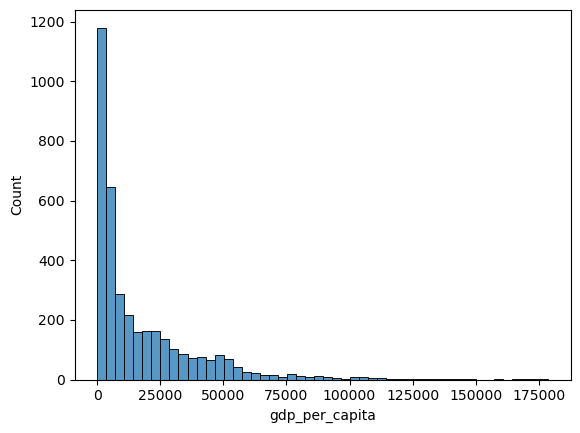

In [11]:
sns.histplot(df['gdp_per_capita'], bins=50)
plt.show()

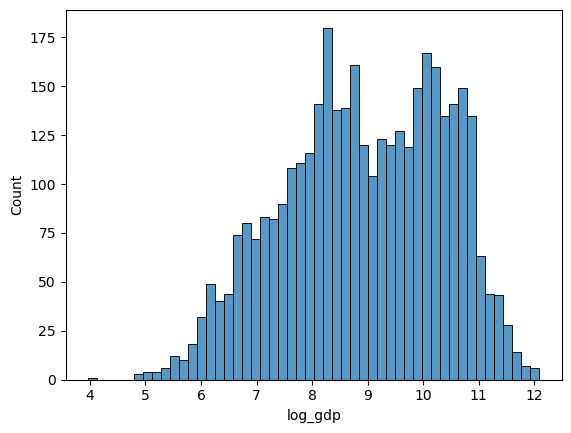

In [12]:
df['log_gdp'] = np.log(df['gdp_per_capita'])

sns.histplot(df['log_gdp'], bins=50)
plt.show()

La distribución del PIB per cápita presenta un sesgo positivo (hacia la derecha), lo que refleja que la mayoría de los países tienen niveles de ingreso relativamente bajos, mientras que un pequeño grupo presenta valores significativamente más altos. Al aplicar una transformación logarítmica, la distribución se aproxima a una forma más simétrica, facilitando su análisis estadístico.

## Relación entre la expectativa de vida y el PIB per cápita

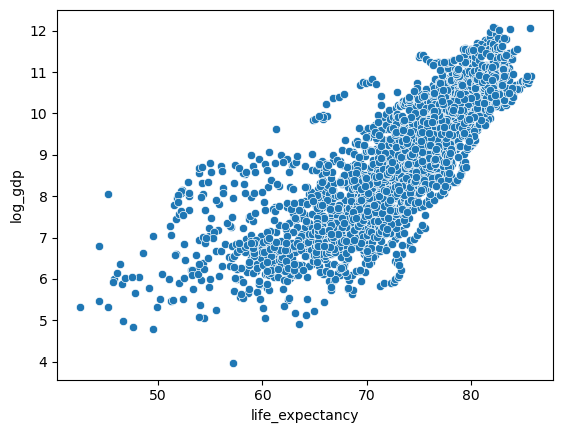

In [13]:
sns.scatterplot(
    data=df,
    x='life_expectancy',
    y='log_gdp'
)
plt.show()

Se observa una relación positiva entre el PIB per cápita y la esperanza de vida, lo que indica que las observaciones con mayores niveles de ingreso tienden a presentar una mayor longevidad. Esta asociación puede estar relacionada con factores como el acceso a servicios de salud, infraestructura y mejores condiciones de vida. Sin embargo, el análisis no permite establecer una relación causal directa.

## Relación entre el uso de internet y el PIB per cápita

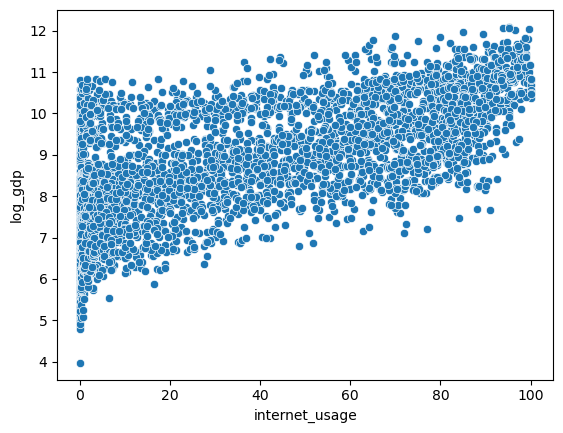

In [14]:
sns.scatterplot(
    data=df,
    x='internet_usage',
    y='log_gdp'
)
plt.show()

El uso de internet presenta una relación positiva con el PIB per cápita, lo que indica que las observaciones con mayores niveles de ingreso tienden a registrar un mayor uso de internet. Esta asociación podría estar relacionada con factores como la infraestructura tecnológica, la educación y la urbanización. Sin embargo, los resultados no permiten establecer una relación causal directa entre ambas variables.

## Relación entre el desempleo y el PIB per cápita

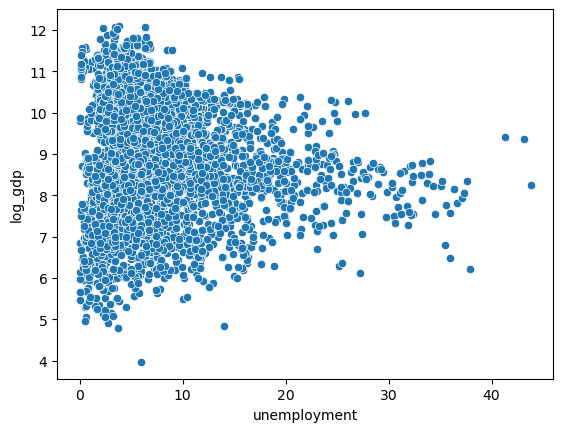

In [15]:
sns.scatterplot(
    data=df,
    x='unemployment',
    y='log_gdp'
)
plt.show()

Se observa una relación negativa débil entre el desempleo y el PIB per cápita, lo que indica que las observaciones con mayores niveles de desempleo tienden a presentar un PIB per cápita ligeramente menor. Sin embargo, la dispersión de los datos sugiere que esta relación no es suficientemente fuerte para explicar por sí sola las diferencias en los niveles de ingreso. Factores como los ciclos económicos, las características del mercado laboral y las políticas económicas podrían contribuir a esta relación, aunque no se evalúan directamente en este análisis.

## Análisis de correlación entre variables

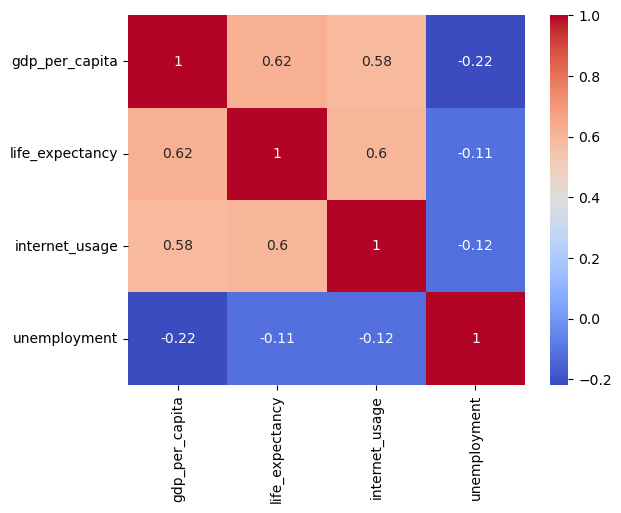

In [16]:
corr = df[['gdp_per_capita', 'life_expectancy', 'internet_usage', 'unemployment']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

La esperanza de vida presenta la correlación positiva más alta con el PIB per cápita entre las variables analizadas (r = 0,62). Esto indica que las observaciones con mayores niveles de ingreso tienden a registrar una mayor esperanza de vida. Sin embargo, esta asociación no implica necesariamente una relación causal.

El uso de internet muestra una correlación positiva con el PIB per cápita (r = 0,58), ligeramente inferior a la observada con la esperanza de vida. Esto sugiere que un mayor nivel de ingreso tiende a estar asociado con una mayor conectividad, aunque la correlación no permite determinar la importancia causal de la tecnología en el desarrollo económico.

Por otro lado, el desempleo presenta una correlación negativa débil con el PIB per cápita (r = -0,22). Esto indica una asociación lineal limitada entre ambas variables, sin que sea posible establecer su capacidad predictiva únicamente a partir de este coeficiente.

En conjunto, los resultados muestran asociaciones entre el PIB per cápita y diferentes indicadores socioeconómicos. No obstante, estas correlaciones deben interpretarse considerando que el dataset contiene observaciones de distintos países y años, y que pueden intervenir otros factores no incluidos en el análisis

## Conclusiones

- La esperanza de vida presenta la correlación positiva más alta con el PIB per cápita entre las variables analizadas (r = 0,62), lo que indica que mayores niveles de ingreso tienden a estar asociados con una mayor longevidad.

- El uso de internet muestra una correlación positiva con el PIB per cápita (r = 0,58), lo que sugiere una asociación entre el nivel de ingreso y la conectividad, sin que pueda establecerse una relación causal directa.

- El desempleo presenta una correlación negativa débil con el PIB per cápita (r = -0,22), lo que indica una asociación lineal limitada entre ambas variables.

- En conjunto, los resultados muestran que el PIB per cápita está asociado con diferentes indicadores socioeconómicos, especialmente la esperanza de vida y el uso de internet. Sin embargo, estas relaciones no permiten establecer causalidad y deben interpretarse considerando las diferencias entre países y períodos.

In [17]:
print("Dimensiones:", df.shape)
print("Entidades:", df["country"].nunique())

Dimensiones: (3752, 8)
Entidades: 199


In [18]:
print(df.columns.tolist())

['country', 'country_code', 'year', 'gdp_per_capita', 'life_expectancy', 'internet_usage', 'unemployment', 'log_gdp']
